In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df="https://docs.google.com/spreadsheets/d/1Gq_-N1dJ_9CBq-pptYPLmJ0oJYvdOReti6-2RZFgphA/export?format=csv"
df=pd.read_csv(df)

In [ ]:
df.head()

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd
0,425.4,2.14,1331,35.2,10,Static-Carousel,High-Intent-Niche,35,16,Android,Net-30,Sunny,15192.26
1,171.3,5.73,3925,25.4,10,YouTube-Deep-Dive,Lifestyle-Warm,26,16,Android,Upfront,Cloudy,20018.44
2,356.4,8.03,1817,9.4,0,Short-Video-Reel,High-Intent-Niche,43,24,Android,Upfront,Cloudy,21146.87
3,272.2,7.70,942,32.1,15,Short-Video-Reel,Lifestyle-Warm,113,9,Android,Net-15,Rainy,17639.62
4,143.0,6.06,3347,51.0,20,Short-Video-Reel,Broad-Entertainment,72,18,Android,Net-30,Cloudy,17375.60


**Define the business problem.**
So the business problem is related to the prediction of campaign revenue. Many marketing agencies are investing on content creators for marketing but they can not predict that how much revenue will they generate

Target variable will be campaign_revenue_usd

**Explain How Machine Learning Can Address the Problem**

This problem can be addressed using Supervised Machine Learning, specifically Regression, because the target variable campaign_revenue_usd is a continuous numerical value.

The model will learn patterns and relationships between the campaign features and historical revenue values. Once trained, it can predict the expected revenue of new marketing campaigns.

In [ ]:
df.shape

(3000, 13)

since we have a small data set

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   creator_followers_k     3000 non-null   float64
 1   engagement_rate_pct     3000 non-null   float64
 2   paid_boost_spend_usd    3000 non-null   int64  
 3   avg_watch_time_sec      3000 non-null   float64
 4   promo_discount_pct      3000 non-null   int64  
 5   content_format          3000 non-null   object 
 6   audience_intent_tier    3000 non-null   object 
 7   caption_word_count      3000 non-null   int64  
 8   hashtags_used_count     3000 non-null   int64  
 9   creator_phone_os        3000 non-null   object 
 10  contract_payment_terms  3000 non-null   object 
 11  posting_day_weather     3000 non-null   object 
 12  campaign_revenue_usd    3000 non-null   float64
dtypes: float64(4), int64(4), object(5)
memory usage: 304.8+ KB


In [ ]:
df.describe()

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,caption_word_count,hashtags_used_count,campaign_revenue_usd
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,232.592433,5.161417,2317.529667,30.266467,12.358333,86.810000,12.367000,16678.699140
std,126.675186,2.539730,1273.365953,14.147323,8.613245,42.942674,6.996473,4747.136562
min,15.000000,0.800000,100.000000,6.100000,0.000000,12.000000,1.000000,2915.630000
25%,122.400000,2.927500,1208.750000,17.900000,5.000000,50.000000,6.000000,13222.897500
50%,229.800000,5.180000,2370.000000,30.400000,10.000000,86.000000,13.000000,16480.745000
75%,343.725000,7.410000,3416.250000,42.700000,20.000000,124.000000,18.000000,19839.157500
max,449.900000,9.500000,4499.000000,55.000000,25.000000,159.000000,24.000000,32527.890000


In [ ]:
df.isnull().sum()

,0
creator_followers_k,0
engagement_rate_pct,0
paid_boost_spend_usd,0
avg_watch_time_sec,0
promo_discount_pct,0
content_format,0
audience_intent_tier,0
caption_word_count,0
hashtags_used_count,0
creator_phone_os,0


In [ ]:
df.duplicated().sum()

np.int64(0)

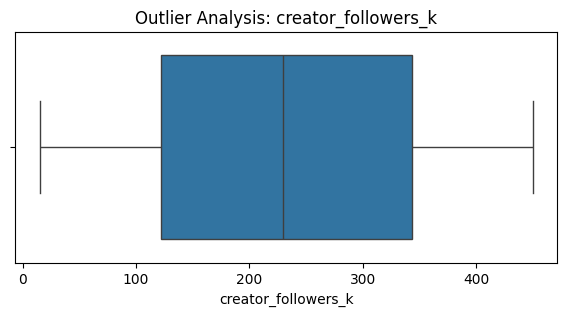

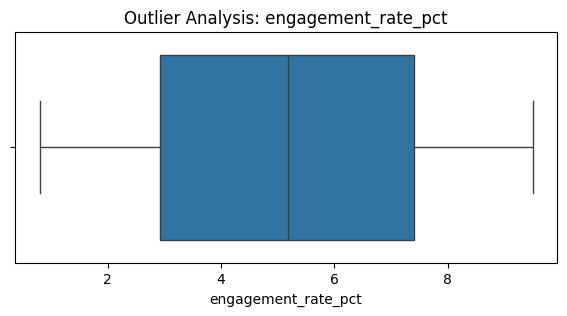

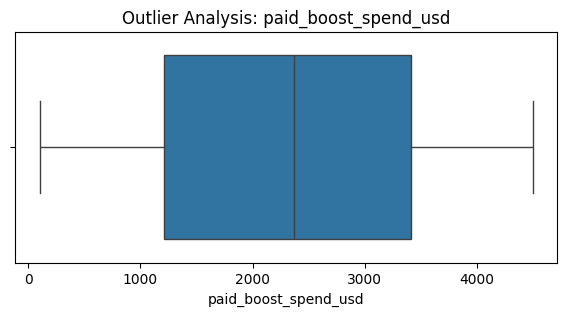

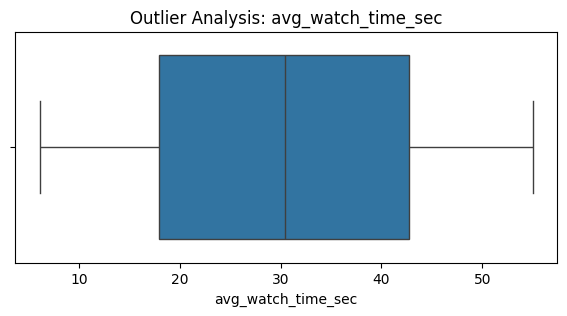

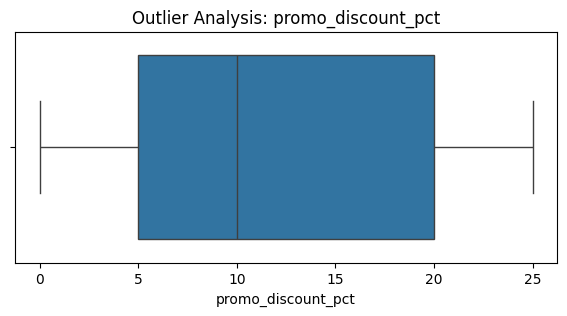

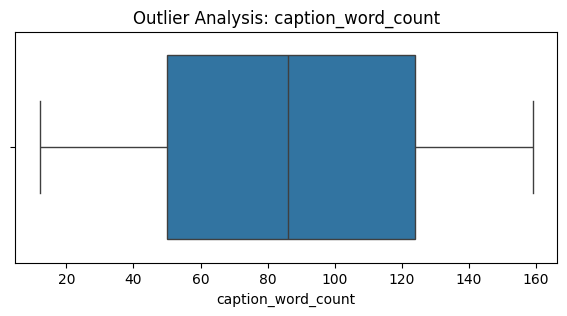

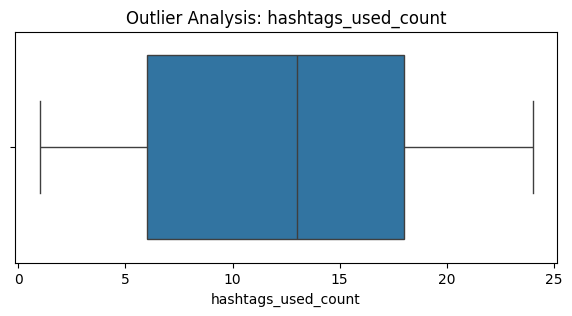

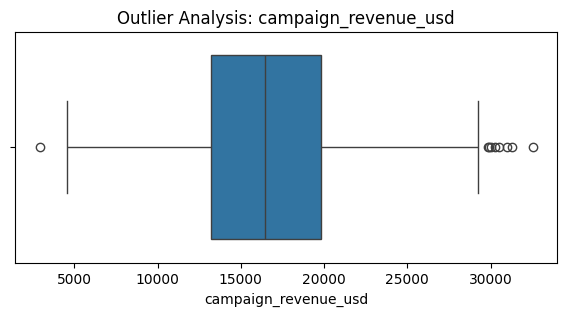

In [ ]:


numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Analysis: {col}")
    plt.show()

In [ ]:
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (df[numeric_cols] < lower_bound) |
    (df[numeric_cols] > upper_bound)
).sum()

display(outlier_counts.sort_values(ascending=False))

,0
campaign_revenue_usd,9
creator_followers_k,0
paid_boost_spend_usd,0
engagement_rate_pct,0
avg_watch_time_sec,0
promo_discount_pct,0
caption_word_count,0
hashtags_used_count,0


Since there a no nulls no I will make a scatter plot to see if it is linear or no linear on basis of that I will select my model

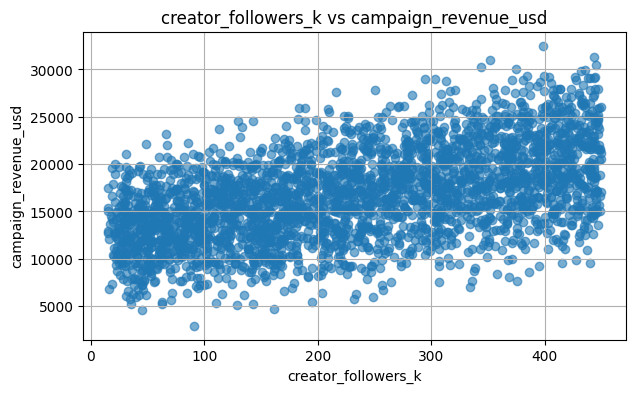

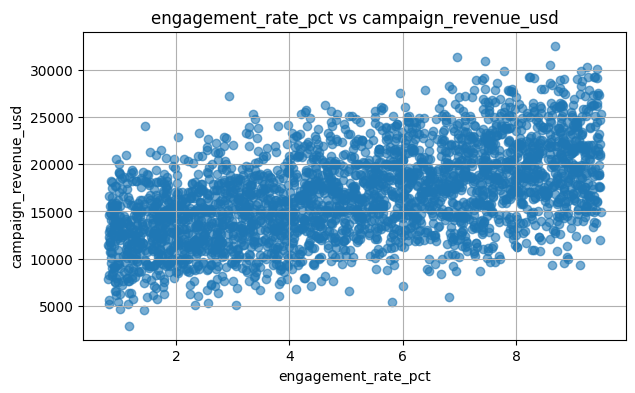

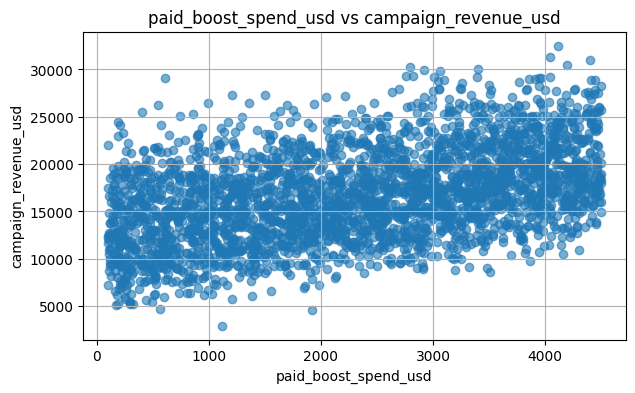

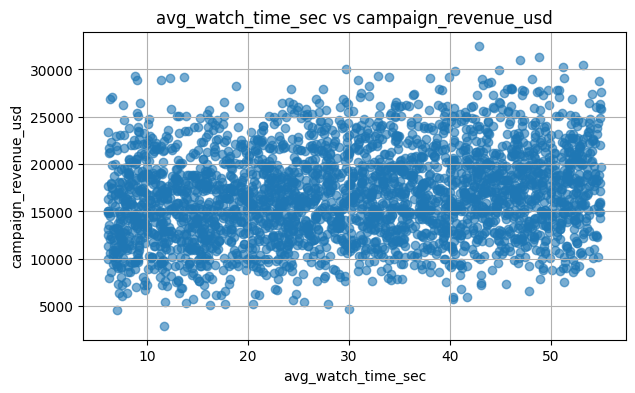

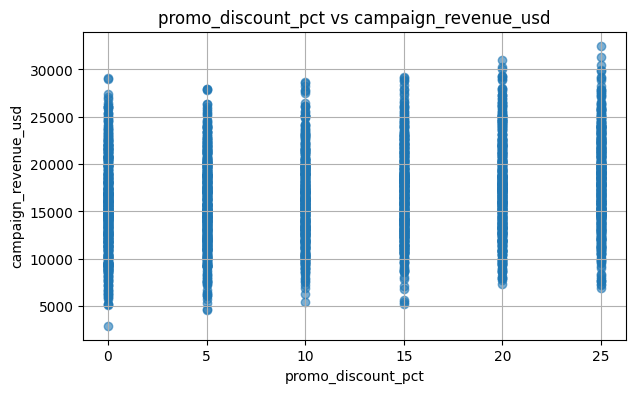

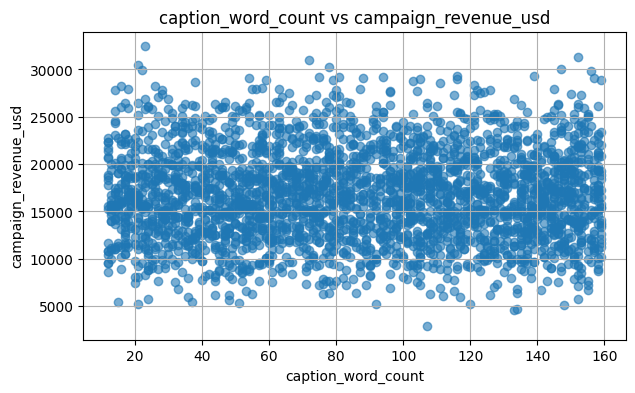

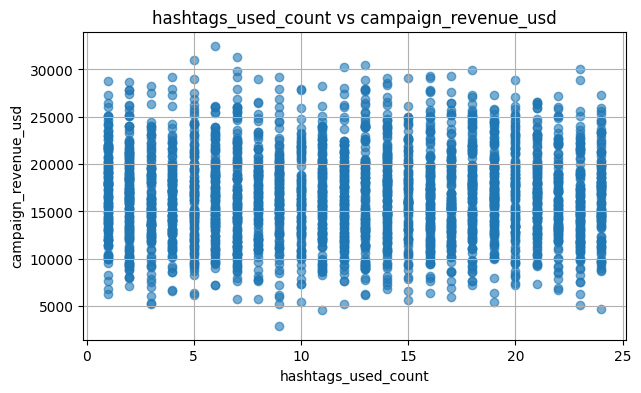

In [ ]:



target = "campaign_revenue_usd"

# Select numerical features, excluding the target
features = df.select_dtypes(include="number").columns.drop(
    target, errors="ignore"
)

# Draw scatter plots
for feature in features:
    plt.figure(figsize=(7, 4))
    plt.scatter(df[feature], df[target], alpha=0.6)
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.title(f"{feature} vs {target}")
    plt.grid(True)
    plt.show()

So scatter plot give us information that this is a linear data and its data set is small so linear regression can be a good fit for this but first i will perform one hot encoding, transform scalling


In [ ]:

NUMERIC_COLS = [
    "creator_followers_k",
    "engagement_rate_pct",
    "paid_boost_spend_usd",
    "avg_watch_time_sec",
    "promo_discount_pct",
    "caption_word_count",
    "hashtags_used_count",
]

CATEGORICAL_COLS = [
    "content_format",
    "audience_intent_tier",
    "creator_phone_os",
    "contract_payment_terms",
    "posting_day_weather",
]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression

In [ ]:

X = df.drop(columns=["campaign_revenue_usd"])
y = df["campaign_revenue_usd"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_COLS ),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),CATEGORICAL_COLS)
    ]
)



Linear regression will be the baseline mode for this type of data so first build it

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SelectFpr, f_regression
from sklearn.metrics import mean_squared_error
import numpy as np

# 1. Define the pipeline with Linear Regression
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
    ('regressor', LinearRegression())
])

# 2. Fit directly on the training data (no GridSearchCV needed)
pipeline_lr.fit(X_train, y_train)

# 3. Predict and evaluate on the test set
y_pred = pipeline_lr.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Test RMSE for Linear Regression: {test_rmse:.2f}")

Test RMSE for Linear Regression: 797.51


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# 1. Define pipeline with PolynomialFeatures + Ridge
pipeline_poly = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
    ('poly', PolynomialFeatures(include_bias=False)),
    ('regressor', Ridge(random_state=42)) # Ridge prevents overfitting with higher degrees
])

# 2. Tune polynomial degree and Ridge regularization
param_grid_poly = {
    'poly__degree': [2, 3],                  # Degree 2 (quadratic) or 3 (cubic)
    'regressor__alpha': [0.1, 1.0, 10.0, 100.0]
}

# 3. Grid Search
grid_search_poly = GridSearchCV(
    pipeline_poly, param_grid_poly, cv=3,
    scoring='neg_mean_squared_error', n_jobs=-1, verbose=1
)
grid_search_poly.fit(X_train, y_train)

print(f"Best parameters for Polynomial Regression: {grid_search_poly.best_params_}")
print(f"Best RMSE for Polynomial Regression: {np.sqrt(-grid_search_poly.best_score_):.2f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters for Polynomial Regression: {'poly__degree': 2, 'regressor__alpha': 1.0}
Best RMSE for Polynomial Regression: 431.66


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# 1. Define pipeline with KNN Regressor
pipeline_knn = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
    ('regressor', KNeighborsRegressor())
])

# 2. Tune neighbors and distance weighting
param_grid_knn = {
    'regressor__n_neighbors': [3, 5, 7, 9, 11],       # Number of neighbors to look at
    'regressor__weights': ['uniform', 'distance']     # Uniform weight vs closer points weighted heavier
}

# 3. Grid Search
grid_search_knn = GridSearchCV(
    pipeline_knn, param_grid_knn, cv=3,
    scoring='neg_mean_squared_error', n_jobs=-1, verbose=1
)
grid_search_knn.fit(X_train, y_train)

print(f"Best parameters for KNN: {grid_search_knn.best_params_}")
print(f"Best RMSE for KNN: {np.sqrt(-grid_search_knn.best_score_):.2f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters for KNN: {'regressor__n_neighbors': 7, 'regressor__weights': 'distance'}
Best RMSE for KNN: 1255.94


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
models = {
    "Linear Regression": pipeline_lr,
    "Polynomial Regression": grid_search_poly,
    "KNN Regressor": grid_search_knn
}
evaluation_results = []

for name, model in models.items():
    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Calculate the three metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# 3. Convert to a DataFrame and display as a table
results_df = pd.DataFrame(evaluation_results)
print(results_df.to_string(index=False))

                Model        MAE        RMSE       R²
    Linear Regression 624.487306  797.512681 0.972514
Polynomial Regression 339.642191  422.835573 0.992274
        KNN Regressor 953.534863 1203.769816 0.937378


In [ ]:



# Evaluate each model on unseen test data
test_results = []

for name, model in models.items():

    # Make predictions on test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    test_results.append({
        "Model": name,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R²": r2
    })

# Display the test results
test_results_df = pd.DataFrame(test_results)

print("Model Performance on Test Data:")
print(test_results_df.to_string(index=False))

# Identify the best model based on test RMSE
best_model_name = test_results_df.loc[
    test_results_df["Test RMSE"].idxmin(), "Model"
]

print("\nBest Model Based on Test RMSE:", best_model_name)


Model Performance on Test Data:
                Model   Test MAE   Test RMSE  Test R²
    Linear Regression 624.487306  797.512681 0.972514
Polynomial Regression 339.642191  422.835573 0.992274
        KNN Regressor 953.534863 1203.769816 0.937378

Best Model Based on Test RMSE: Polynomial Regression


In [ ]:
import joblib

# Save the trained Polynomial Regression model
joblib.dump( grid_search_poly, "polynomial_model.pkl")

print("Polynomial Regression model saved successfully!")

Polynomial Regression model saved successfully!


In [ ]:

custom_input = pd.DataFrame([{
    "creator_followers_k": 200.0,
    "engagement_rate_pct": 4.5,
    "paid_boost_spend_usd": 500,
    "avg_watch_time_sec": 25.0,
    "promo_discount_pct": 10,
    "content_format": "Video",
    "audience_intent_tier": "High",
    "caption_word_count": 100,
    "hashtags_used_count": 8,
    "creator_phone_os": "iOS",
    "contract_payment_terms": "Fixed",
    "posting_day_weather": "Sunny"
}])

# Generate prediction
predicted_revenue = grid_search_poly.predict(custom_input)

In [ ]:
print("\nPredicted Campaign Revenue")
print(f"${predicted_revenue[0]:,.2f}")


Predicted Campaign Revenue
$11,825.93


Now I will start for classification data set

In [ ]:
df="https://docs.google.com/spreadsheets/d/1uKG-NbzLBIG-ZKo_0lMvS2OTk-QdLNZLbQTSPjVsg38/export?format=csv"
df=pd.read_csv(df)

In [ ]:
df.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


E-commerce product returns create massive logistical costs, processing overhead, and revenue loss. The core business problem is predicting whether a customer order has a high probability of being returned so the company can proactively mitigate return rates.

Target Variable: return_risk_label

Machine learning can uncover patterns from historical order data—such as a customer's past return behavior, high cart values, fit issues, or delivery delays. By classifying high-risk transactions at checkout, the business can take proactive steps (e.g., triggering precise size recommendation pop-ups, adjusting packaging/product descriptions, or modifying return policies) to reduce overall returns and save on operational costs.

In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   object 
 6   fit_review_sentiment   2993 non-null   object 
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   object 
 9   checkout_device        2993 non-null   object 
 10  packaging_color        2993 non-null   object 
 11  loyalty_card_color     2993 non-null   object 
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 304.1+ KB


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,newsletter_subscriber,return_risk_label
count,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.750301,0.284024,0.354160,5.974273,23.879051,0.503508,0.645506
std,121.394772,0.159998,0.478338,3.188330,17.263143,0.500071,0.478440
min,25.010000,0.005000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,135.560000,0.157000,0.000000,3.000000,10.000000,0.000000,0.000000
50%,238.740000,0.265000,0.000000,6.000000,20.000000,1.000000,1.000000
75%,343.920000,0.386000,1.000000,9.000000,40.000000,1.000000,1.000000
max,449.860000,0.884000,1.000000,11.000000,50.000000,1.000000,1.000000


In [ ]:
df.shape

(2993, 13)

This is also a small data set now will draw scatter plot to check if the data is linear or not

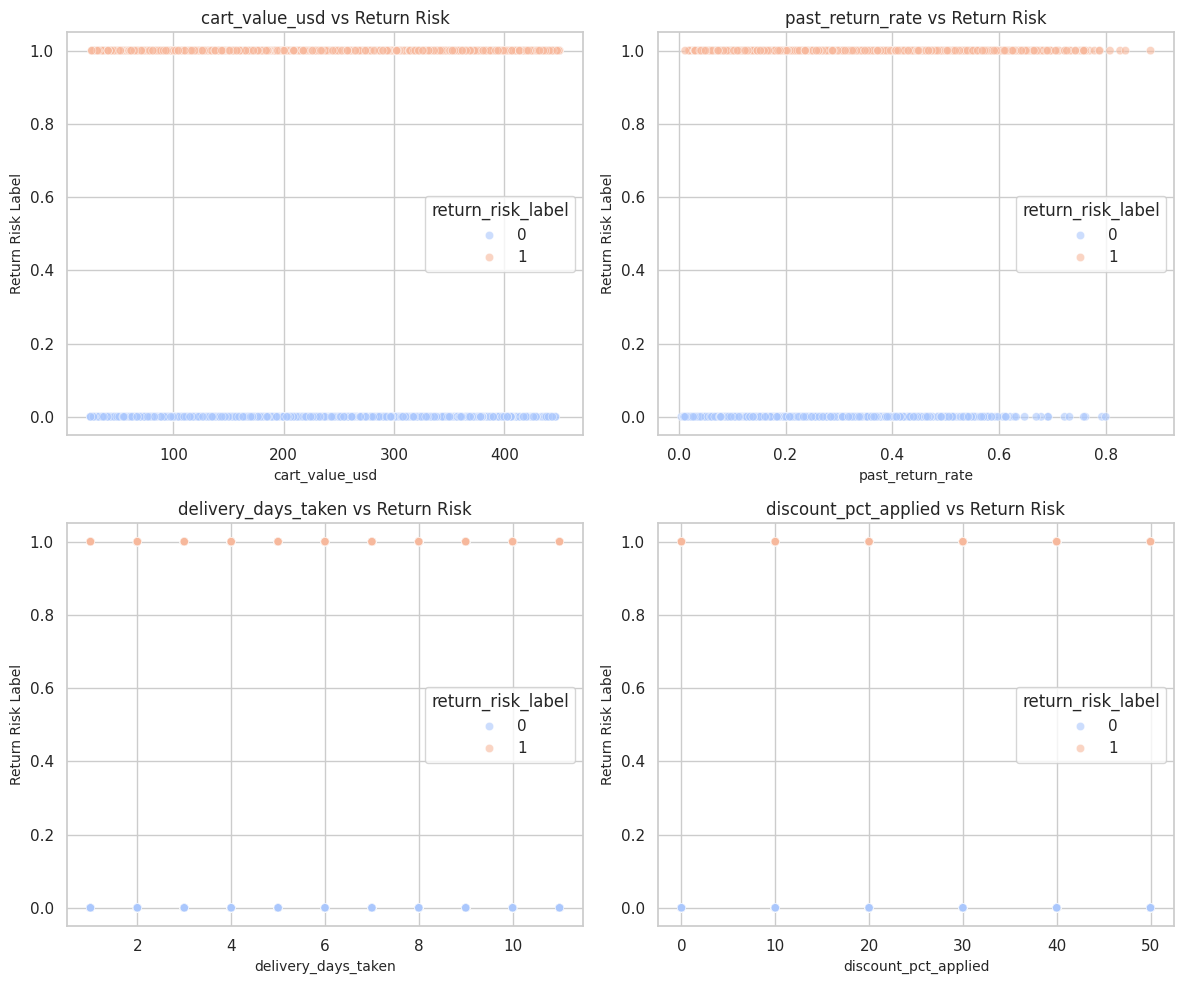

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style
sns.set_theme(style="whitegrid")

# Select numeric features you want to plot against the target
numeric_features = ['cart_value_usd', 'past_return_rate', 'delivery_days_taken', 'discount_pct_applied']

# Create a grid of subplots (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten to easily loop through them

# Loop through each feature and create a scatter plot on its own subplot
for i, feature in enumerate(numeric_features):
    sns.scatterplot(
        data=df,
        x=feature,
        y='return_risk_label',
        hue='return_risk_label',
        palette='coolwarm',
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f'{feature} vs Return Risk', fontsize=12)
    axes[i].set_xlabel(feature, fontsize=10)
    axes[i].set_ylabel('Return Risk Label', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
df.isnull().sum()

,0
cart_value_usd,0
past_return_rate,0
size_bracketing_flag,0
delivery_days_taken,0
discount_pct_applied,0
product_category,0
fit_review_sentiment,0
newsletter_subscriber,0
browser_used,0
checkout_device,0


In [ ]:
df.duplicated().sum()

np.int64(0)

Detecting outlier using box plot and IQR method

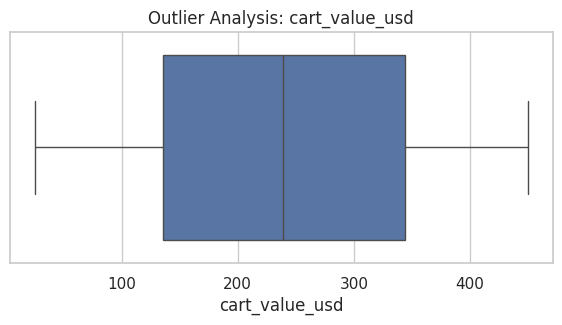

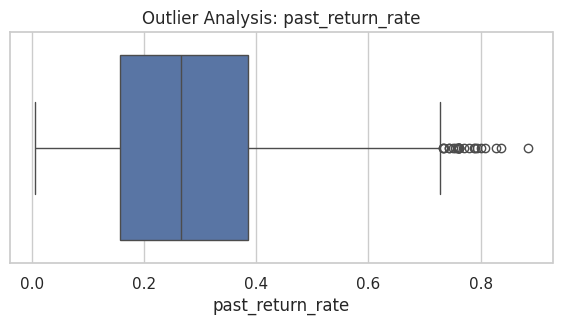

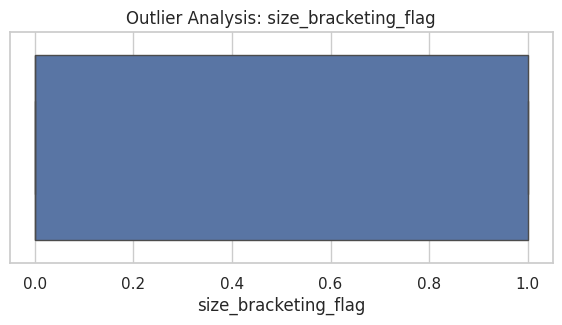

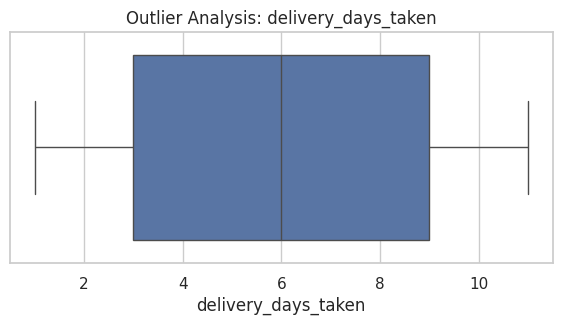

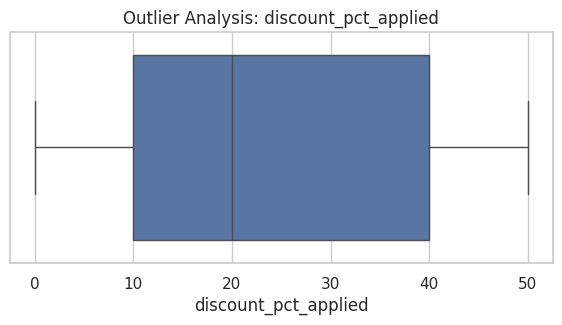

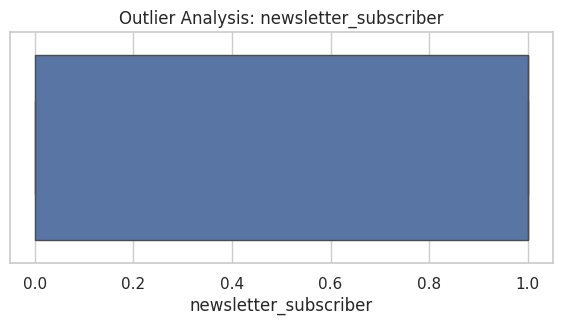

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

target = "return_risk_label"

numeric_features = [
    col for col in df.select_dtypes(include="number").columns
    if col != target
]

for col in numeric_features:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Analysis: {col}")
    plt.show()

In [ ]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[numeric_features] < Q1 - 1.5 * IQR) |
    (df[numeric_features] > Q3 + 1.5 * IQR)
)

print("Potential outliers per feature:")
print(outliers.sum().sort_values(ascending=False))

Potential outliers per feature:
past_return_rate         25
cart_value_usd            0
size_bracketing_flag      0
delivery_days_taken       0
discount_pct_applied      0
newsletter_subscriber     0
dtype: int64


Relation ship between numerial features and target variable

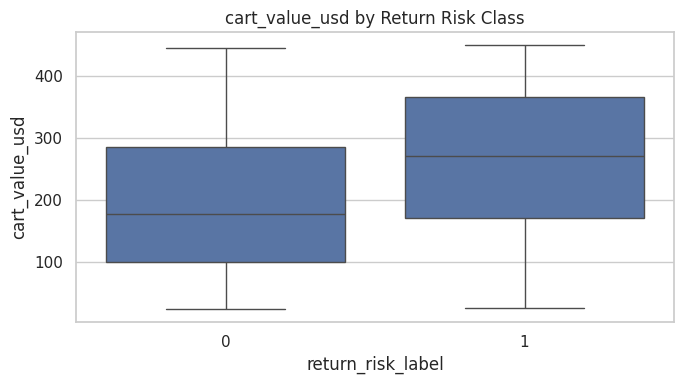

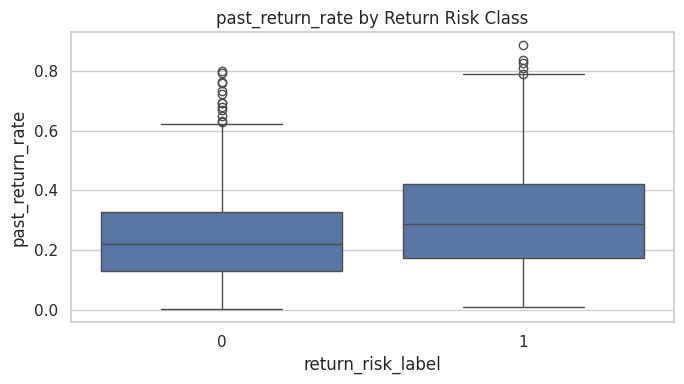

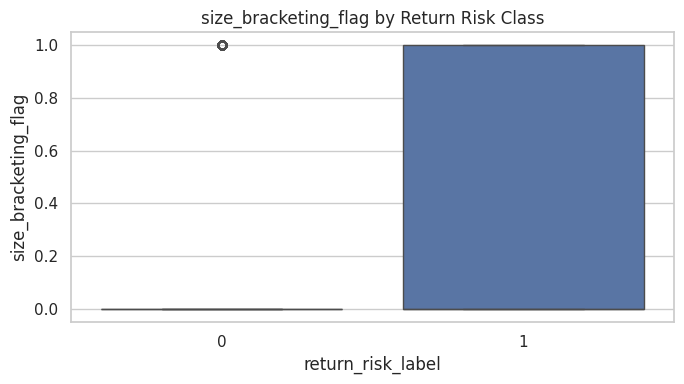

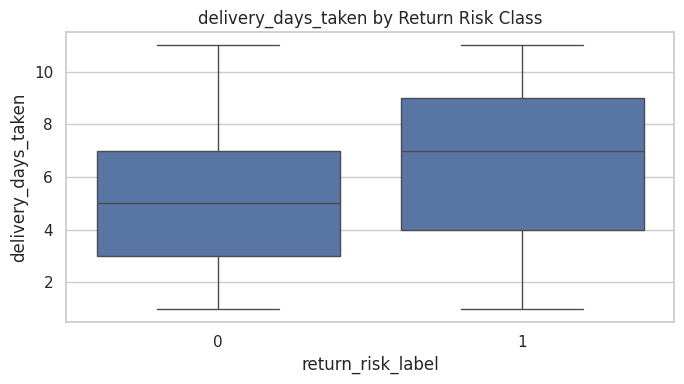

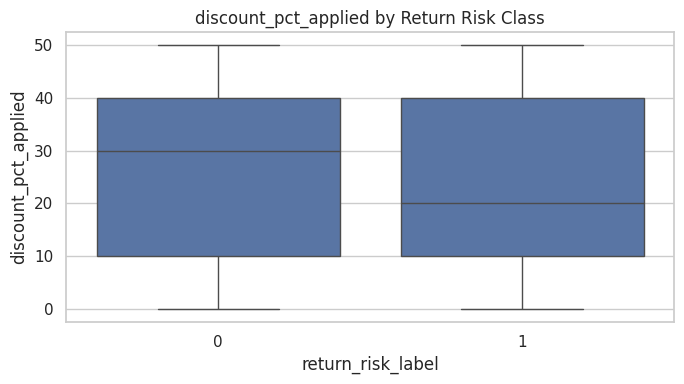

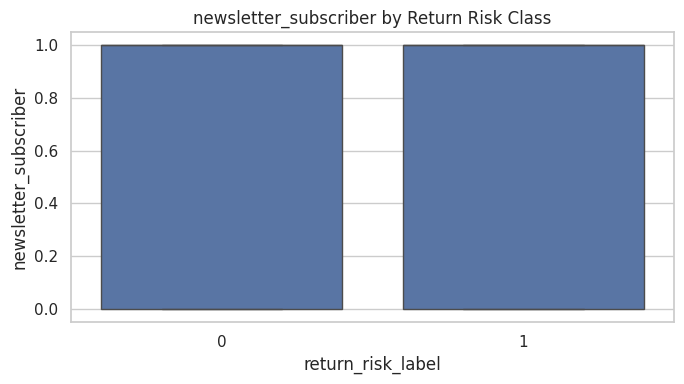

In [ ]:
for col in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=target, y=col)
    plt.title(f"{col} by Return Risk Class")
    plt.tight_layout()
    plt.show()

Relationship between categorical features and target variable

In [ ]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

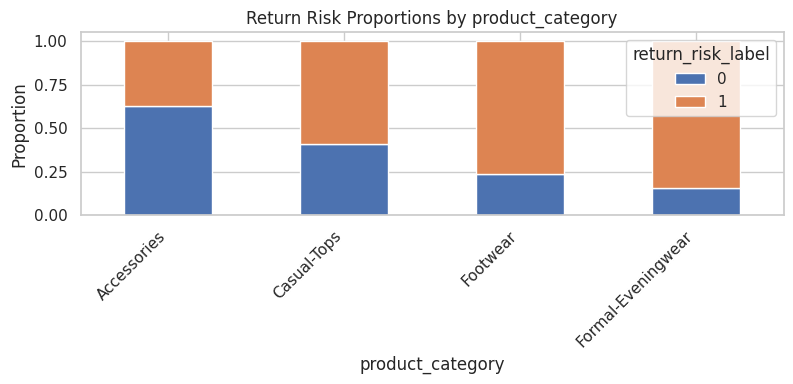

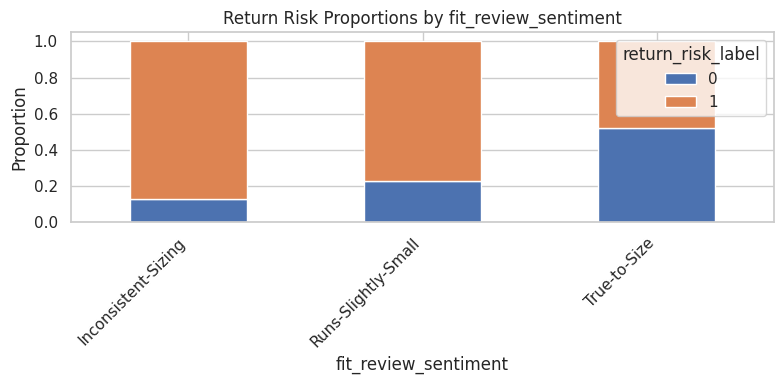

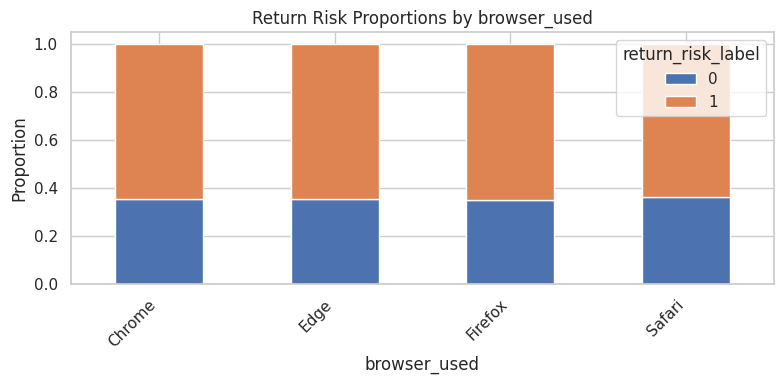

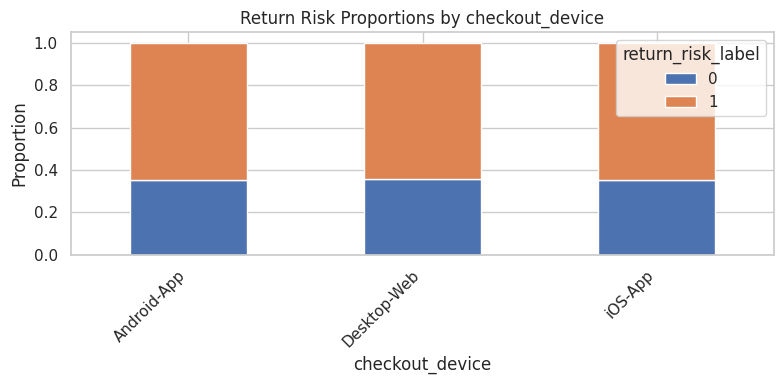

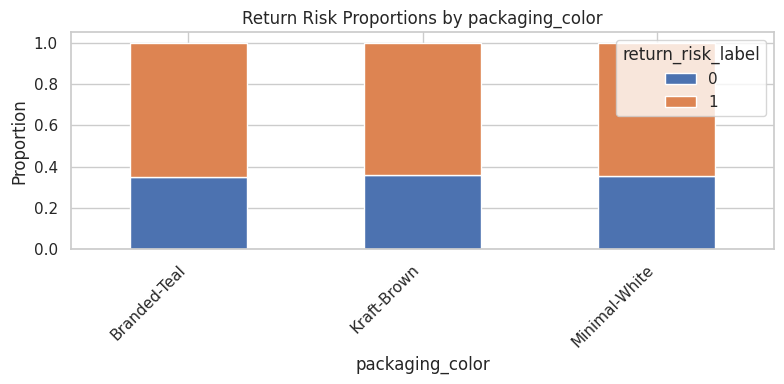

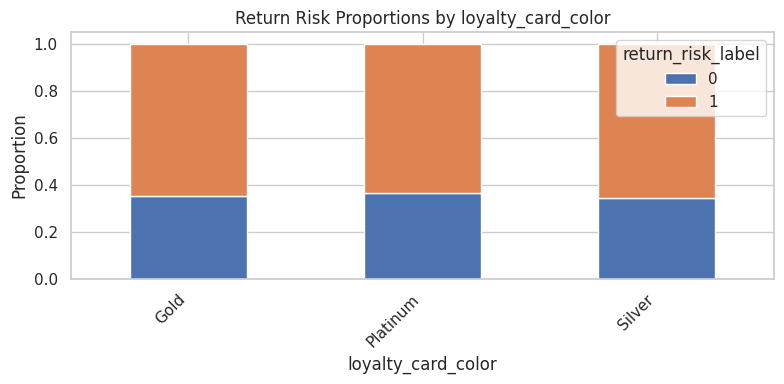

In [ ]:
for col in categorical_cols:
    proportions = pd.crosstab(
        df[col],
        df[target],
        normalize="index"
    )

    proportions.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"Return Risk Proportions by {col}")
    plt.xlabel(col)
    plt.ylabel("Proportion")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Now after this I wiil do one hot encoding and feature selection so that that our data set will be fit for model

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

target = 'return_risk_label'
num_cols = ['cart_value_usd', 'past_return_rate', 'delivery_days_taken', 'discount_pct_applied']

# One-hot encode the text columns
X = pd.get_dummies(df.drop(columns=[target]), drop_first=True)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaled copy (for Logistic Regression and KNN only)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

In [ ]:
from sklearn.dummy import DummyClassifier

model = DummyClassifier(strategy='most_frequent')
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print("Baseline")
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("F1 score:", round(f1_score(y_test, pred), 4))
print("ROC AUC :", round(roc_auc_score(y_test, proba), 4))

Baseline
Accuracy: 0.6461
F1 score: 0.785
ROC AUC : 0.5


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

results = {}

In [ ]:
from sklearn.linear_model import LogisticRegression

params = {'C': [0.01, 0.1, 1, 10]}

grid = GridSearchCV(LogisticRegression(max_iter=2000), params, cv=5, scoring='f1')
grid.fit(X_train_scaled, y_train)

best = grid.best_estimator_
pred = best.predict(X_test_scaled)
proba = best.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression")
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 4))
print("Accuracy   :", round(accuracy_score(y_test, pred), 4))
print("F1 score   :", round(f1_score(y_test, pred), 4))
print("ROC AUC    :", round(roc_auc_score(y_test, proba), 4))

results['Logistic Regression'] = [grid.best_score_, accuracy_score(y_test, pred),
                                  f1_score(y_test, pred), roc_auc_score(y_test, proba)]

Logistic Regression
Best params: {'C': 10}
Best CV F1 : 0.951
Accuracy   : 0.9316
F1 score   : 0.9476
ROC AUC    : 0.9864


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

params = {'n_neighbors': [5, 10, 15, 20, 30]}

grid = GridSearchCV(KNeighborsClassifier(), params, cv=5, scoring='f1')
grid.fit(X_train_scaled, y_train)

best = grid.best_estimator_
pred = best.predict(X_test_scaled)
proba = best.predict_proba(X_test_scaled)[:, 1]

print("KNN")
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 4))
print("Accuracy   :", round(accuracy_score(y_test, pred), 4))
print("F1 score   :", round(f1_score(y_test, pred), 4))
print("ROC AUC    :", round(roc_auc_score(y_test, proba), 4))

results['KNN'] = [grid.best_score_, accuracy_score(y_test, pred),
                  f1_score(y_test, pred), roc_auc_score(y_test, proba)]

KNN
Best params: {'n_neighbors': 30}
Best CV F1 : 0.8739
Accuracy   : 0.8431
F1 score   : 0.8776
ROC AUC    : 0.9151


In [ ]:
from sklearn.tree import DecisionTreeClassifier

params = {'max_depth': [3, 5, 7, 10],
          'min_samples_leaf': [5, 10, 20]}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5, scoring='f1')
grid.fit(X_train, y_train)          # trees use the unscaled data

best = grid.best_estimator_
pred = best.predict(X_test)
proba = best.predict_proba(X_test)[:, 1]

print("Decision Tree")
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 4))
print("Accuracy   :", round(accuracy_score(y_test, pred), 4))
print("F1 score   :", round(f1_score(y_test, pred), 4))
print("ROC AUC    :", round(roc_auc_score(y_test, proba), 4))

results['Decision Tree'] = [grid.best_score_, accuracy_score(y_test, pred),
                            f1_score(y_test, pred), roc_auc_score(y_test, proba)]

Decision Tree
Best params: {'max_depth': 10, 'min_samples_leaf': 10}
Best CV F1 : 0.8838
Accuracy   : 0.8414
F1 score   : 0.8777
ROC AUC    : 0.9088


In [ ]:
import pandas as pd

comparison = pd.DataFrame(results, index=['CV F1', 'Accuracy', 'F1 score', 'ROC AUC']).T
comparison = comparison.round(4).sort_values('ROC AUC', ascending=False)
display(comparison)

print("Best model:", comparison.index[0])

,CV F1,Accuracy,F1 score,ROC AUC
Logistic Regression,0.9510,0.9316,0.9476,0.9864
KNN,0.8739,0.8431,0.8776,0.9151
Decision Tree,0.8838,0.8414,0.8777,0.9088


Best model: Logistic Regression


In [ ]:
models = {}

models['Logistic Regression'] = best
models['KNN'] = best
models['Decision Tree'] = best
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

def test_model(name, model, X_t):
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)[:, 1]
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("F1 score:", round(f1_score(y_test, pred), 4))
    print("ROC AUC :", round(roc_auc_score(y_test, proba), 4))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred), "\n")

In [ ]:
test_model("Logistic Regression", models['Logistic Regression'], X_test_scaled)

Logistic Regression
Accuracy: 0.6928
F1 score: 0.7089
ROC AUC : 0.8177
Confusion matrix:
 [[191  21]
 [163 224]] 



In [ ]:

test_model("KNN", models['KNN'], X_test_scaled)
test_model("Decision Tree", models['Decision Tree'], X_test)

KNN
Accuracy: 0.6928
F1 score: 0.7089
ROC AUC : 0.8177
Confusion matrix:
 [[191  21]
 [163 224]] 

Decision Tree
Accuracy: 0.8414
F1 score: 0.8777
ROC AUC : 0.9088
Confusion matrix:
 [[163  49]
 [ 46 341]] 

